In [8]:
import os
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_1636097a290255252c05be6981d510a6'
!pip -q install kaggle
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p/content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [01:01<00:00, 90.8MB/s]



In [9]:
import glob,os,numpy as np,pandas as pd,torch
from sklearn.model_selection import train_test_split

SEED = 42
torch.manual_seed(SEED);np.random.seed(SEED)

df = pd.read_csv('/content/data/HAM10000_metadata.csv')

# Fix path matching by mapping the full image filename (without extension) to its full path
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob('/content/data/**/*.jpg', recursive=True)}
df['path'] = df['image_id'].map(paths)

classes = sorted(df['dx'].unique())
cls2idx = {c:i for i,c in enumerate(classes)}
df['label'] = df['dx'].map(cls2idx)

# FIX: Keep 'lesion_id' in the columns so it is present in tr_l, va_l, and te_l
lesions = df.drop_duplicates('lesion_id')[['lesion_id', 'image_id', 'dx']]
tr_l,tmp_l = train_test_split(lesions,test_size=0.3,stratify=lesions['dx'],random_state=SEED)
va_l,te_l = train_test_split(tmp_l,test_size=0.5,stratify=tmp_l['dx'],random_state=SEED)

train_df = df[df.lesion_id.isin(tr_l.lesion_id)].reset_index(drop=True)
val_df = df[df.lesion_id.isin(va_l.lesion_id)].reset_index(drop=True)
test_df = df[df.lesion_id.isin(te_l.lesion_id)].reset_index(drop=True)

print(len(train_df),len(val_df),len(test_df))
print(train_df['dx'].value_counts())
print('missing paths:',df['path'].isna().sum())
assert not set(train_df.lesion_id) & set(test_df.lesion_id)

7002 1532 1481
dx
nv       4679
mel       778
bkl       774
bcc       366
akiec     230
vasc       99
df         76
Name: count, dtype: int64
missing paths: 0


In [10]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(), T.Normalize(mean, std)])
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(mean, std)])

class HAM(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d, tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(r.path).convert('RGB')), r.label

train_dl = DataLoader(HAM(train_df, train_tf), batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(HAM(val_df,   eval_tf),  batch_size=64, num_workers=2)
test_dl  = DataLoader(HAM(test_df,  eval_tf),  batch_size=64, num_workers=2)

counts = train_df['label'].value_counts().sort_index().values
weights = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, weights)

cuda tensor([ 4.3491,  2.7330,  1.2924, 13.1617,  1.2857,  0.2138, 10.1039])


In [11]:
import time, torch.nn as nn
from torchvision import models
from sklearn.metrics import f1_score, accuracy_score, classification_report, recall_score

NUM_CLASSES = 7

def build_model(name):
    if name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        head, top = m.fc, m.layer4
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        head, top = m.classifier, m.features[-3:]
    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        head, top = m.classifier, m.features[-4:]
    return m.to(device), head, top

def run_epoch(m, dl, crit, opt=None, scaler=None):
    train = opt is not None
    m.train(train)
    preds, ys, total = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast('cuda', enabled=(device == 'cuda')):
                out = m(x)
                loss = crit(out, y)
            if train:
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
            total += loss.item() * len(y)
            preds += out.argmax(1).cpu().tolist(); ys += y.cpu().tolist()
    return total / len(dl.dataset), f1_score(ys, preds, average='macro'), ys, preds

def fit(name, head_epochs=3, ft_epochs=10):
    m, head, top = build_model(name)
    crit = nn.CrossEntropyLoss(weight=weights.to(device))
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    best_f1, ckpt = 0, f'/content/{name}.pt'

    # Stage 1: train only the new head
    for p in m.parameters(): p.requires_grad = False
    for p in head.parameters(): p.requires_grad = True
    stages = [('head', head_epochs, 1e-3)]

    # Stage 2: also unfreeze the top block, lower LR
    stages.append(('finetune', ft_epochs, 1e-4))

    for stage, epochs, lr in stages:
        if stage == 'finetune':
            for p in top.parameters(): p.requires_grad = True
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        for ep in range(epochs):
            t0 = time.time()
            tl, tf1, _, _ = run_epoch(m, train_dl, crit, opt, scaler)
            vl, vf1, _, _ = run_epoch(m, val_dl, crit)
            if vf1 > best_f1:
                best_f1 = vf1; torch.save(m.state_dict(), ckpt)
            print(f'{name} [{stage}] ep{ep+1}: train_loss {tl:.3f} | val_loss {vl:.3f} | val_macroF1 {vf1:.3f} | {time.time()-t0:.0f}s')

    # Final test with the best checkpoint
    m.load_state_dict(torch.load(ckpt))
    _, _, ys, ps = run_epoch(m, test_dl, crit)
    mel = cls2idx['mel']
    res = dict(model=name,
               acc=accuracy_score(ys, ps),
               macro_f1=f1_score(ys, ps, average='macro'),
               mel_recall=recall_score(ys, ps, labels=[mel], average=None)[0],
               params_M=sum(p.numel() for p in m.parameters()) / 1e6)
    print(classification_report(ys, ps, target_names=classes, digits=3))
    return res

results = []
results.append(fit('resnet50'))
print(results[-1])

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 91.0MB/s]


resnet50 [head] ep1: train_loss 1.565 | val_loss 1.174 | val_macroF1 0.392 | 106s
resnet50 [head] ep2: train_loss 1.276 | val_loss 1.120 | val_macroF1 0.423 | 83s
resnet50 [head] ep3: train_loss 1.155 | val_loss 1.039 | val_macroF1 0.430 | 84s
resnet50 [finetune] ep1: train_loss 0.927 | val_loss 0.881 | val_macroF1 0.506 | 83s
resnet50 [finetune] ep2: train_loss 0.700 | val_loss 0.801 | val_macroF1 0.534 | 86s
resnet50 [finetune] ep3: train_loss 0.579 | val_loss 0.779 | val_macroF1 0.568 | 84s
resnet50 [finetune] ep4: train_loss 0.493 | val_loss 0.805 | val_macroF1 0.578 | 84s
resnet50 [finetune] ep5: train_loss 0.457 | val_loss 0.732 | val_macroF1 0.581 | 85s
resnet50 [finetune] ep6: train_loss 0.392 | val_loss 0.703 | val_macroF1 0.603 | 84s
resnet50 [finetune] ep7: train_loss 0.379 | val_loss 0.714 | val_macroF1 0.608 | 92s
resnet50 [finetune] ep8: train_loss 0.326 | val_loss 0.719 | val_macroF1 0.583 | 85s
resnet50 [finetune] ep9: train_loss 0.306 | val_loss 0.799 | val_macroF1 0.5

In [12]:
from google.colab import drive
drive.mount('/content/drive')

# Added the missing space between the source and destination paths
!cp /content/resnet50.pt /content/drive/MyDrive/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
results.append(fit('efficientnet_b0'))
results.append(fit('mobilenet_v2'))

res_df = pd.DataFrame(results).round(3)
print(res_df)
res_df.to_csv('/content/results_round1.csv',index=False)

efficientnet_b0 [head] ep1: train_loss 1.498 | val_loss 1.298 | val_macroF1 0.388 | 98s
efficientnet_b0 [head] ep2: train_loss 1.212 | val_loss 1.219 | val_macroF1 0.391 | 88s
efficientnet_b0 [head] ep3: train_loss 1.124 | val_loss 1.225 | val_macroF1 0.401 | 86s
efficientnet_b0 [finetune] ep1: train_loss 0.983 | val_loss 0.985 | val_macroF1 0.483 | 92s
efficientnet_b0 [finetune] ep2: train_loss 0.783 | val_loss 0.870 | val_macroF1 0.519 | 90s
efficientnet_b0 [finetune] ep3: train_loss 0.692 | val_loss 0.850 | val_macroF1 0.548 | 89s
efficientnet_b0 [finetune] ep4: train_loss 0.641 | val_loss 0.860 | val_macroF1 0.530 | 87s
efficientnet_b0 [finetune] ep5: train_loss 0.588 | val_loss 0.817 | val_macroF1 0.542 | 84s
efficientnet_b0 [finetune] ep6: train_loss 0.500 | val_loss 0.765 | val_macroF1 0.579 | 87s
efficientnet_b0 [finetune] ep7: train_loss 0.500 | val_loss 0.845 | val_macroF1 0.563 | 84s
efficientnet_b0 [finetune] ep8: train_loss 0.446 | val_loss 0.767 | val_macroF1 0.589 | 87s


100%|██████████| 13.6M/13.6M [00:00<00:00, 96.3MB/s]


mobilenet_v2 [head] ep1: train_loss 1.551 | val_loss 1.435 | val_macroF1 0.334 | 85s
mobilenet_v2 [head] ep2: train_loss 1.217 | val_loss 1.227 | val_macroF1 0.426 | 82s
mobilenet_v2 [head] ep3: train_loss 1.172 | val_loss 1.019 | val_macroF1 0.419 | 84s
mobilenet_v2 [finetune] ep1: train_loss 1.029 | val_loss 1.013 | val_macroF1 0.487 | 83s
mobilenet_v2 [finetune] ep2: train_loss 0.781 | val_loss 0.841 | val_macroF1 0.533 | 85s
mobilenet_v2 [finetune] ep3: train_loss 0.720 | val_loss 0.768 | val_macroF1 0.566 | 83s
mobilenet_v2 [finetune] ep4: train_loss 0.666 | val_loss 0.851 | val_macroF1 0.532 | 84s
mobilenet_v2 [finetune] ep5: train_loss 0.617 | val_loss 0.783 | val_macroF1 0.542 | 84s
mobilenet_v2 [finetune] ep6: train_loss 0.584 | val_loss 0.846 | val_macroF1 0.561 | 85s
mobilenet_v2 [finetune] ep7: train_loss 0.538 | val_loss 0.797 | val_macroF1 0.564 | 82s
mobilenet_v2 [finetune] ep8: train_loss 0.520 | val_loss 0.842 | val_macroF1 0.547 | 85s
mobilenet_v2 [finetune] ep9: trai

In [14]:
!cp /content/*.pt /content/drive/MyDrive/

In [15]:
!cp /content/*.pt /content/results_round1.csv /content/drive/MyDrive/

In [16]:
import time, numpy as np
from sklearn.metrics import f1_score, accuracy_score, recall_score, classification_report
from torchvision import transforms as T
from torch.utils.data import DataLoader
import torch

IMG = 256
train_tf2 = T.Compose([T.Resize
 ((IMG, IMG)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                       T.RandomRotation(20), T.ColorJitter(0.2, 0.2, 0.2),
                       T.ToTensor(), T.Normalize(mean, std)])
eval_tf2 = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(mean, std)])

train_dl2 = DataLoader(HAM(train_df, train_tf2), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_dl2   = DataLoader(HAM(val_df,   eval_tf2),  batch_size=64, num_workers=2)
test_dl2  = DataLoader(HAM(test_df,  eval_tf2),  batch_size=64, num_workers=2)

def predict(m, dl, tta=False):
    m.eval(); probs, ys = [], []
    with torch.no_grad():
        for x, y in dl:
            x = x.to(device)
            with torch.autocast('cuda', enabled=(device == 'cuda')):
                p = m(x).float().softmax(1)
                if tta:
                    p = (p + m(torch.flip(x, [3])).float().softmax(1)
                           + m(torch.flip(x, [2])).float().softmax(1)) / 3
            probs.append(p.cpu()); ys += y.tolist()
    return torch.cat(probs).numpy(), np.array(ys)

def evaluate(m, tta=False):
    p, y = predict(m, test_dl2, tta)
    pr = p.argmax(1); mel = cls2idx['mel']
    return dict(tta=tta,
                acc=round(accuracy_score(y, pr), 3),
                macro_f1=round(f1_score(y, pr, average='macro'), 3),
                mel_recall=round(recall_score(y, pr, labels=[mel], average=None)[0], 3))

In [20]:
def train_round2b(epochs=10, seed=42, init_ckpt=None, tag='r2b'):
    torch.manual_seed(seed); np.random.seed(seed)
    m, head, top = build_model('efficientnet_b0')
    if init_ckpt:
        m.load_state_dict(torch.load(init_ckpt, map_location=device))
    for p in m.parameters(): p.requires_grad = True

    w = weights.sqrt().to(device)                 # softer class weights
    crit = nn.CrossEntropyLoss(weight=w)          # no label smoothing
    backbone = [p for n, p in m.named_parameters() if not n.startswith('classifier')]
    opt = torch.optim.AdamW([
        {'params': backbone, 'lr': 2e-5},         # gentle on pretrained layers
        {'params': m.classifier.parameters(), 'lr': 1e-4}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    best, ckpt = 0, f'/content/drive/MyDrive/effb0_{tag}_s{seed}.pt'

    for ep in range(epochs):
        m.train(); t0 = time.time(); tl = 0
        for x, y in train_dl2:
            x, y = x.to(device), y.to(device)
            with torch.autocast('cuda', enabled=(device == 'cuda')):
                loss = crit(m(x), y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            tl += loss.item() * len(y)
        sched.step()
        pv, yv = predict(m, val_dl2)
        vf1 = f1_score(yv, pv.argmax(1), average='macro')
        if vf1 > best:
            best = vf1; torch.save(m.state_dict(), ckpt)
        print(f'ep{ep+1}: loss {tl/len(train_dl2.dataset):.3f} | val_macroF1 {vf1:.3f} | {time.time()-t0:.0f}s')

    m.load_state_dict(torch.load(ckpt, map_location=device))
    return m, ckpt

model2b, ck = train_round2b(init_ckpt='/content/drive/MyDrive/efficientnet_b0.pt')
print(evaluate(model2b, tta=False))
print(evaluate(model2b, tta=True))

ep1: loss 0.457 | val_macroF1 0.619 | 118s
ep2: loss 0.418 | val_macroF1 0.622 | 103s
ep3: loss 0.369 | val_macroF1 0.616 | 101s
ep4: loss 0.363 | val_macroF1 0.621 | 101s
ep5: loss 0.342 | val_macroF1 0.615 | 99s
ep6: loss 0.336 | val_macroF1 0.632 | 97s
ep7: loss 0.324 | val_macroF1 0.621 | 98s
ep8: loss 0.323 | val_macroF1 0.620 | 98s
ep9: loss 0.302 | val_macroF1 0.624 | 98s
ep10: loss 0.311 | val_macroF1 0.624 | 102s
{'tta': False, 'acc': 0.817, 'macro_f1': 0.706, 'mel_recall': np.float64(0.618)}
{'tta': True, 'acc': 0.822, 'macro_f1': 0.709, 'mel_recall': np.float64(0.648)}


In [24]:
pv,yv = predict(model2b, val_dl2,tta=True)
pt,yt = predict(model2b, test_dl2,tta=True)
mel = cls2idx['mel']

def objective(s,p,y):
  pr = (p*s).argmax(1)
  return (f1_score(y,pr,average='macro')
  +0.3*recall_score(y,pr,labels=[mel],average=None)[0])

scale = np.ones(7)
grid = [0.5,0.7,1.0,1.3,1.6,2.0,2.5,3.0]
for _ in range(2):
  for c in range(7):
    best_s,best_o = scale[c],objective(scale,pv,yv)
    for g in grid:
      s = scale.copy()
      s[c] = g
      o = objective(s,pv,yv)
      if o > best_o:
        best_s,best_o = g,o
    scale[c] = best_s
print(dict(zip(classes,scale)))

for name,s in [('before',np.ones(7)),('after',scale)]:
  pr = (pt*s).argmax(1)
  print(name,'acc',round(accuracy_score(yt,pr),3),
        'f1',round(f1_score(yt,pr,average='macro'),3),
        'mel_recall',round(recall_score(yt,pr,labels=[mel],average=None)[0],3))

{'akiec': np.float64(0.5), 'bcc': np.float64(1.3), 'bkl': np.float64(0.7), 'df': np.float64(2.5), 'mel': np.float64(3.0), 'nv': np.float64(0.7), 'vasc': np.float64(0.5)}
before acc 0.822 f1 0.709 mel_recall 0.648
after acc 0.758 f1 0.694 mel_recall 0.885


In [25]:
!pip -q install grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


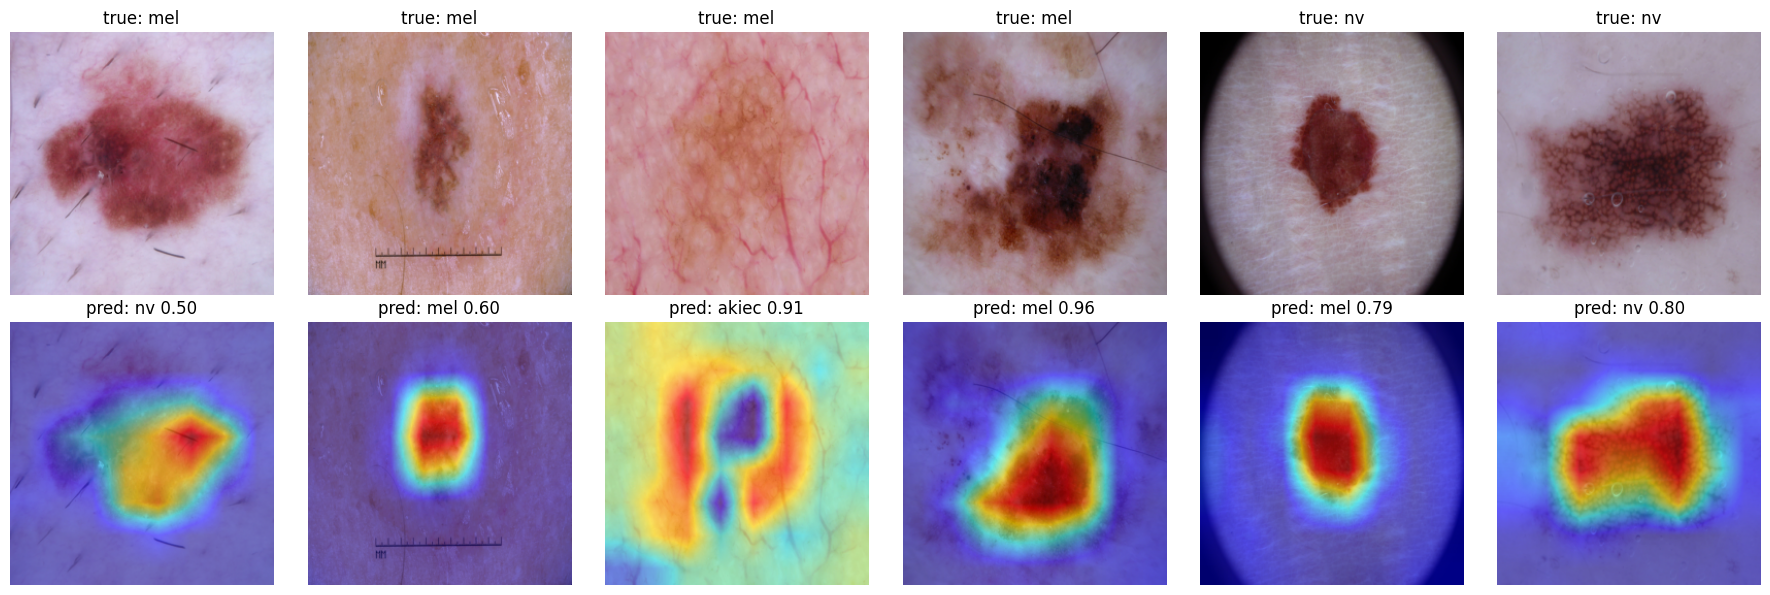

In [27]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import matplotlib.pyplot as plt

model2b.eval()
cam = GradCAM(model=model2b, target_layers=[model2b.features[-1]])
inv = lambda t: (t * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()

ds = HAM(test_df, eval_tf2)
idxs = (test_df[test_df.dx == 'mel'].sample(4, random_state=1).index.tolist()
        + test_df[test_df.dx == 'nv'].sample(2, random_state=1).index.tolist())

fig, ax = plt.subplots(2, len(idxs), figsize=(3 * len(idxs), 6))
for j, i in enumerate(idxs):
    x, y = ds[i]
    xb = x.unsqueeze(0).to(device)
    with torch.no_grad():
        p = model2b(xb).softmax(1)[0]
    pred = p.argmax().item()
    g = cam(input_tensor=xb, targets=[ClassifierOutputTarget(pred)])[0]
    img = inv(x)
    ax[0, j].imshow(img); ax[0, j].axis('off'); ax[0, j].set_title(f'true: {classes[y]}')
    ax[1, j].imshow(show_cam_on_image(img, g, use_rgb=True)); ax[1, j].axis('off')
    ax[1, j].set_title(f'pred: {classes[pred]} {p[pred]:.2f}')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/gradcam_samples.png', dpi=150)
plt.show()